# Прогнозування чисельності населення України

**Ієрархічний прогноз за схемою: Області → Країна (підхід Bottom-Up)**

Робота виконана в інтересах державних установ. Скрипт реалізує:

1. **Парсинг** файлу датасету `1_dataset_POPULATION.xlsx`;
2. **Попередній аналіз даних** та їх обробку (пропуски, структурні розриви, стаціонарність тренду);
3. **Модель прогнозування** за ієрархією `область → країна` з реконсиляцією **Bottom-Up**;
4. **Прогнозування динаміки** зміни популяції за регіонами та країною (таблиці + графіки).

---

### Методологічна довідка: Bottom-Up

Прогноз будується **лише на нижньому рівні ієрархії** (окремі області).
Значення верхнього рівня (Україна) отримується **агрегуванням** прогнозів областей:

$$\hat{y}_{\text{Україна},t+h} = \sum_{i=1}^{K} \hat{y}_{i,\,t+h}$$

* **Переваги:** зберігає деталізацію по регіонах, автоматично забезпечує когерентність ієрархії (сума областей *точно* дорівнює країні).
* **Недоліки:** накопичення похибок з нижніх рівнів; ряди окремих областей більш зашумлені.


## 0. Налаштування середовища


In [1]:
# За потреби розкоментуйте встановлення залежностей
# !pip install pandas numpy matplotlib openpyxl statsmodels
# !pip install scikit-hts   # опціонально: реалізація HTSRegressor

import pandas as pd
import numpy as np
import warnings

import matplotlib.pyplot as plt
import matplotlib

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.0f}')

matplotlib.rcParams['figure.dpi'] = 110
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.alpha'] = 0.3
matplotlib.rcParams['font.size'] = 10

# Шлях до датасету
DATA_PATH = '1_dataset_POPULATION.xlsx'

print('Середовище готове')
print('pandas:', pd.__version__, '| numpy:', np.__version__)


Середовище готове
pandas: 3.0.5 | numpy: 2.5.2


## 1. Парсинг файлу датасету `1_dataset_POPULATION.xlsx`

Датасет Держстату має **широкий формат**: перші 12 стовпців — метаопис ряду
(показник, територіальний розріз, вік, стать, тип місцевості, періодичність тощо),
решта ~440 стовпців — значення за роками (`1989`, `1990`, …) та місяцями (`1989-M01`, …).

Клас `PopulationDataLoader` побудований за зразком `AlertDataLoader` із наданого коду:
метод `load_data()` завантажує та приводить дані до ієрархічної «широкої» матриці
(рядки — дати, стовпці — `total` + області), метод `create_hierarchy()` формує
словник ієрархії для реконсиляції.


In [2]:
"""
Data loading and preprocessing for Ukrainian population statistics
(адаптовано з data_loader.AlertDataLoader)
"""


class PopulationDataLoader:
    """Load and preprocess Ukrainian population data for hierarchical forecasting"""

    # Метарядки: території, які НЕ є областями нижнього рівня ієрархії
    COUNTRY_LABEL = 'Україна'

    # Території без спостережень після 2014 р. (тимчасово окуповані)
    OCCUPIED = ['Автономна Республіка Крим', 'Севастополь']

    def __init__(self, data_path=DATA_PATH,
                 indicator='Чисельність наявного населення (за оцінкою) станом на 1 січня',
                 start_year=1989):
        self.data_path = data_path
        self.indicator = indicator
        self.start_year = start_year
        self.raw_df = None
        self.hierarchy_df = None
        self.country_official = None

    # ------------------------------------------------------------------ #
    def load_data(self):
        """Load and preprocess Ukrainian population data"""
        print("Loading Ukrainian population data...")

        # --- 1. Парсинг Excel ---------------------------------------- #
        df = pd.read_excel(self.data_path, sheet_name=0)
        self.raw_df = df
        print(f"Raw dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

        # --- 2. Фільтрація потрібного зрізу --------------------------- #
        # Показник: наявне населення на 1 січня; усі віки; обидві статі;
        # загалом (місто + село); річна періодичність.
        mask = (
            (df['Показник'] == self.indicator) &
            (df['Вік'] == 'Усього') &
            (df['Стать'] == 'Усього') &
            (df['Тип місцевості'] == 'Загалом') &
            (df['Періодичність'] == 'Річна')
        )
        sub = df[mask].copy()
        print(f"Filtered to annual totals by territory: {len(sub)} records")

        # --- 3. Відбір стовпців-років (виключаємо місячні '1989-M01') -- #
        year_cols = [c for c in df.columns if str(c).isdigit()]
        year_cols = [c for c in year_cols if int(c) >= self.start_year]

        # --- 4. Транспонування: рядки = роки, стовпці = території ------ #
        wide = sub.set_index('Територіальний розріз')[year_cols].T
        wide.index = pd.to_datetime(wide.index.astype(str) + '-01-01')
        wide = wide.astype(float).sort_index()
        wide.index.name = 'date'
        wide.index.freq = 'YS'          # річна частота, початок року

        # Офіційний ряд по країні зберігаємо окремо (для порівняння)
        self.country_official = wide[self.COUNTRY_LABEL].copy()

        # --- 5. Формування нижнього рівня ієрархії (області) ---------- #
        oblasts = [c for c in wide.columns
                   if c != self.COUNTRY_LABEL and c not in self.OCCUPIED]
        wide = wide[oblasts]

        # --- 6. Верхній рівень = сума областей (Bottom-Up когерентність) #
        wide['total'] = wide[oblasts].sum(axis=1)

        # Порядок стовпців: total спершу, далі області
        cols = ['total'] + [c for c in wide.columns if c != 'total']
        self.hierarchy_df = wide[cols]

        print(f"Data loaded: {len(self.hierarchy_df)} years")
        print(f"Period: {self.hierarchy_df.index.min():%Y} to {self.hierarchy_df.index.max():%Y}")
        print(f"Regions (bottom level): {len(self.hierarchy_df.columns) - 1}")
        print(f"Excluded from bottom level: {', '.join(self.OCCUPIED)} (немає даних після 2014 р.)")
        print(f"Population (last obs.): {self.hierarchy_df['total'].iloc[-1]:,.0f} осіб")

        return self.hierarchy_df

    # ------------------------------------------------------------------ #
    def create_hierarchy(self):
        """
        Create hierarchy dictionary for reconciliation.
        Total has all oblasts as children
        """
        print("\nCreating hierarchy structure...")

        oblasts = [col for col in self.hierarchy_df.columns if col != 'total']
        hierarchy = {'total': oblasts}

        print("Hierarchy created:")
        print(f"  - Total (Україна): 1 series")
        print(f"  - Oblasts: {len(oblasts)} series")
        print(f"  - Total time series: {len(oblasts) + 1}")

        return hierarchy


In [3]:
data_loader = PopulationDataLoader(data_path=DATA_PATH)
hierarchy_df = data_loader.load_data()
hierarchy = data_loader.create_hierarchy()

hierarchy_df.tail(10)


Loading Ukrainian population data...
Raw dataset: 67,012 rows x 454 columns
Filtered to annual totals by territory: 28 records
Data loaded: 34 years
Period: 1989 to 2022
Regions (bottom level): 25
Excluded from bottom level: Автономна Республіка Крим, Севастополь (немає даних після 2014 р.)
Population (last obs.): 41,167,335 осіб

Creating hierarchy structure...
Hierarchy created:
  - Total (Україна): 1 series
  - Oblasts: 25 series
  - Total time series: 26


Територіальний розріз,total,Рівненська,Вінницька,Чернівецька,Львівська,Житомирська,Запорізька,Сумська,Харківська,Миколаївська,Дніпропетровська,Луганська,Хмельницька,Івано-Франківська,Волинська,Київ,Черкаська,Херсонська,Тернопільська,Одеська,Закарпатська,Кіровоградська,Донецька,Київська,Чернігівська,Полтавська
date,,,,,,,,,,,,,,,,,,,,,,,,,,
2013-01-01,"43,204,433","1,156,868","1,627,038","907,163","2,540,702","1,268,903","1,785,243","1,143,249","2,744,419","1,173,481","3,307,795","2,256,551","1,313,964","1,381,788","1,039,958","2,845,023","1,268,888","1,078,232","1,077,327","2,395,160","1,254,393","995,171","4,375,442","1,722,052","1,077,802","1,467,821"
2014-01-01,"43,073,120","1,158,851","1,618,262","908,508","2,538,436","1,262,512","1,775,833","1,132,957","2,737,242","1,168,372","3,292,431","2,239,473","1,306,992","1,382,096","1,041,303","2,868,702","1,259,957","1,072,567","1,073,327","2,396,493","1,256,850","987,565","4,343,882","1,725,478","1,066,826","1,458,205"
2015-01-01,"42,929,298","1,161,151","1,610,573","909,965","2,537,799","1,255,966","1,765,926","1,123,448","2,731,302","1,164,342","3,276,637","2,220,151","1,301,242","1,382,553","1,042,918","2,887,974","1,251,816","1,067,876","1,069,936","2,396,442","1,259,570","980,579","4,297,250","1,729,234","1,055,673","1,448,975"
2016-01-01,"42,760,516","1,161,811","1,602,163","909,893","2,534,174","1,247,549","1,753,642","1,113,256","2,718,616","1,158,207","3,254,884","2,205,389","1,294,413","1,382,352","1,042,668","2,906,569","1,242,965","1,062,356","1,065,709","2,390,289","1,259,158","973,150","4,265,145","1,732,235","1,044,975","1,438,948"
2017-01-01,"42,584,542","1,162,763","1,590,357","908,120","2,534,027","1,240,482","1,739,488","1,104,529","2,701,188","1,150,126","3,230,411","2,195,290","1,285,267","1,379,915","1,040,954","2,925,760","1,231,207","1,055,649","1,059,192","2,386,516","1,258,777","965,756","4,244,057","1,734,471","1,033,412","1,426,828"
2018-01-01,"42,386,403","1,160,647","1,575,808","906,701","2,529,608","1,231,239","1,723,171","1,094,284","2,694,007","1,141,324","3,231,140","2,167,802","1,274,409","1,377,496","1,038,457","2,934,522","1,220,363","1,046,981","1,052,312","2,383,075","1,258,155","956,250","4,200,461","1,754,284","1,020,078","1,413,829"
2019-01-01,"42,153,201","1,157,301","1,560,394","904,374","2,522,021","1,220,193","1,705,836","1,081,418","2,675,598","1,131,096","3,206,477","2,151,833","1,264,705","1,373,252","1,035,330","2,950,819","1,206,351","1,037,640","1,045,879","2,380,308","1,256,802","945,549","4,165,901","1,767,940","1,005,745","1,400,439"
2020-01-01,"41,902,416","1,152,961","1,545,416","901,632","2,512,084","1,208,212","1,687,401","1,068,247","2,658,461","1,119,862","3,176,648","2,135,913","1,254,702","1,368,097","1,031,421","2,967,360","1,192,137","1,027,913","1,038,695","2,377,230","1,253,791","933,109","4,131,808","1,781,044","991,294","1,386,978"
2021-01-01,"41,588,354","1,148,456","1,529,123","896,566","2,497,750","1,195,495","1,666,515","1,053,452","2,633,834","1,108,394","3,142,035","2,121,322","1,243,787","1,361,109","1,027,397","2,962,180","1,178,266","1,016,707","1,030,562","2,368,107","1,250,129","920,128","4,100,280","1,788,530","976,701","1,371,529"


## 2. Попередній аналіз даних та їх обробка

Перевіряємо: повноту рядів, пропуски, описові статистики, структурні розриви
та темпи щорічної зміни. Це визначає вибір періоду навчання моделі.


In [4]:
print("=" * 70)
print("СТРУКТУРА ІЄРАРХІЧНОГО НАБОРУ ДАНИХ")
print("=" * 70)
print(f"Розмірність : {hierarchy_df.shape[0]} спостережень x {hierarchy_df.shape[1]} рядів")
print(f"Період      : {hierarchy_df.index.min():%Y}–{hierarchy_df.index.max():%Y}")
print(f"Частота     : річна (станом на 1 січня)")
print(f"Тип даних   : {hierarchy_df.dtypes.unique()[0]}")

print("\nПропущені значення по рядах:")
na = hierarchy_df.isna().sum()
if na.sum() == 0:
    print("  Пропусків немає ✓")
else:
    print(na[na > 0].to_string())

print("\nОписова статистика (Україна, total):")
print(hierarchy_df['total'].describe().to_string())


СТРУКТУРА ІЄРАРХІЧНОГО НАБОРУ ДАНИХ
Розмірність : 34 спостережень x 26 рядів
Період      : 1989–2022
Частота     : річна (станом на 1 січня)
Тип даних   : float64

Пропущені значення по рядах:
  Пропусків немає ✓

Описова статистика (Україна, total):
count           34
mean    45,406,222
std      2,792,480
min     41,167,335
25%     43,105,948
50%     44,737,294
75%     48,144,750
max     49,605,300


In [5]:
# Описова статистика по регіонах
desc = pd.DataFrame({
    'Мінімум': hierarchy_df.drop(columns='total').min(),
    'Максимум': hierarchy_df.drop(columns='total').max(),
    'Середнє': hierarchy_df.drop(columns='total').mean(),
    'Станом на 2022': hierarchy_df.drop(columns='total').iloc[-1],
    'Зміна 1989→2022, %': (hierarchy_df.drop(columns='total').iloc[-1] /
                           hierarchy_df.drop(columns='total').iloc[0] - 1) * 100,
})
desc = desc.sort_values('Станом на 2022', ascending=False)
desc.style.format({'Зміна 1989→2022, %': '{:+.1f}'})


,Мінімум,Максимум,Середнє,Станом на 2022,"Зміна 1989→2022, %"
Територіальний розріз,,,,,
Донецька,4059372.000000,5365800.000000,4715649.000000,4059372.000000,-23.9
Дніпропетровська,3096485.000000,3936400.000000,3520830.852941,3096485.000000,-20.2
Київ,2602800.000000,2967360.000000,2743194.970588,2952301.000000,+13.4
Харківська,2598961.000000,3197200.000000,2888221.882353,2598961.000000,-18.7
Львівська,2478133.000000,2778300.000000,2621811.088235,2478133.000000,-9.8
Одеська,2351392.000000,2642600.000000,2470388.000000,2351392.000000,-11.0
Луганська,2102921.000000,2886000.000000,2479046.500000,2102921.000000,-26.5
Київська,1717649.000000,1947600.000000,1814334.558824,1795079.000000,-7.3
Запорізька,1638462.000000,2116100.000000,1893404.794118,1638462.000000,-21.3


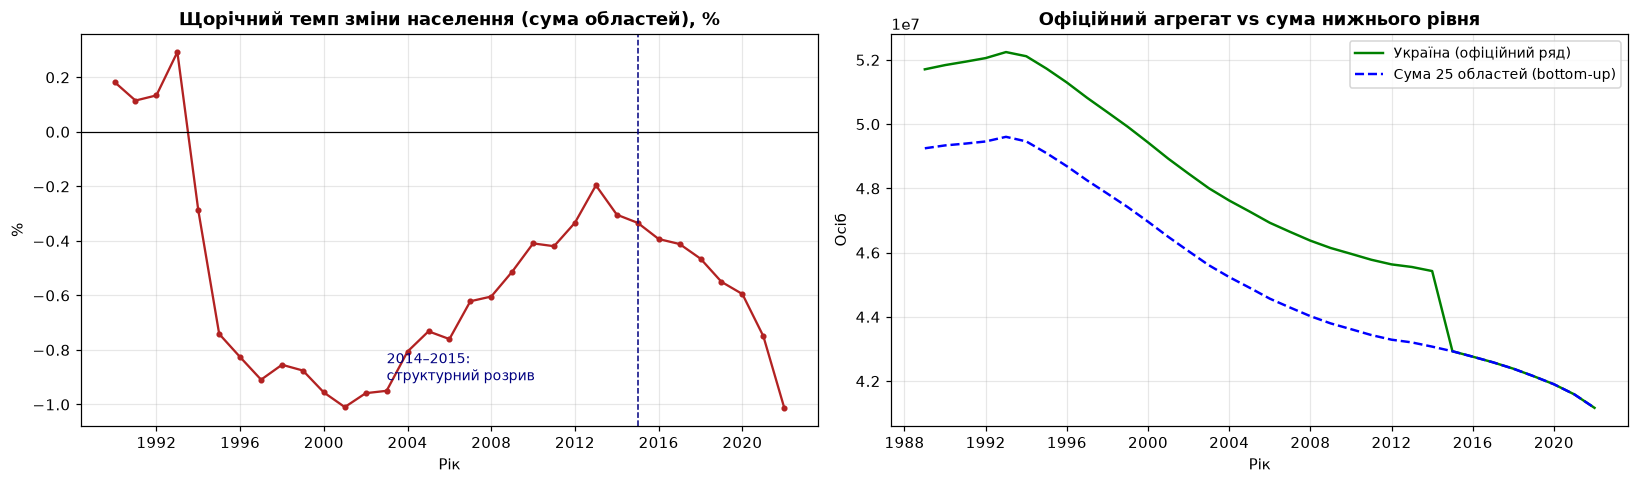

Найбільші за модулем річні зміни:
date
2022-01-01   1
2001-01-01   1
2002-01-01   1
2000-01-01   1
2003-01-01   1


In [6]:
# Щорічні темпи зміни — діагностика структурних розривів
growth = hierarchy_df['total'].pct_change() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].plot(growth.index, growth.values, marker='o', ms=3, color='firebrick')
axes[0].axhline(0, color='black', lw=0.8)
axes[0].axvline(pd.Timestamp('2015-01-01'), color='navy', ls='--', lw=1)
axes[0].annotate('2014–2015:\nструктурний розрив', xy=(pd.Timestamp('2015-01-01'), growth.min()),
                 xytext=(pd.Timestamp('2003-01-01'), growth.min() * 0.9),
                 fontsize=9, color='navy')
axes[0].set_title('Щорічний темп зміни населення (сума областей), %', fontweight='bold')
axes[0].set_xlabel('Рік'); axes[0].set_ylabel('%')

# Порівняння: офіційний ряд «Україна» vs сума областей без ТОТ
axes[1].plot(data_loader.country_official.index, data_loader.country_official.values,
             label='Україна (офіційний ряд)', color='green', lw=1.6)
axes[1].plot(hierarchy_df.index, hierarchy_df['total'].values,
             label='Сума 25 областей (bottom-up)', color='blue', lw=1.6, ls='--')
axes[1].set_title('Офіційний агрегат vs сума нижнього рівня', fontweight='bold')
axes[1].set_xlabel('Рік'); axes[1].set_ylabel('Осіб')
axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

print("Найбільші за модулем річні зміни:")
print(growth.abs().sort_values(ascending=False).head(5).to_string())


### Висновки попереднього аналізу та рішення щодо обробки

1. **Пропуски.** У відібраному зрізі пропусків немає. АР Крим і м. Севастополь мають
   спостереження лише до 2014 р. включно — їх **виключено з нижнього рівня ієрархії**,
   інакше ряди були б обірваними і bottom-up агрегат став би некогерентним.
2. **Структурний розрив 2014–2015.** Офіційний ряд «Україна» різко падає через втрату
   обліку ТОТ. Ряд «сума 25 областей» такого розриву **не має** — це підтверджує
   коректність побудованої ієрархії.
3. **Період навчання.** Ряди 1989–2001 містять перехідну демографічну динаміку
   (різкий спад 1990-х), яка не характерна для сучасного режиму. Для прогнозування
   використовуємо період **з 2002 року** (після Всеукраїнського перепису), де тренд
   стабільно від'ємний і майже лінійний.
4. **Сезонність відсутня** — дані річні, тому в моделі Holt-Winters вимикаємо
   сезонну компоненту і залишаємо **адитивний тренд** (метод Холта).


In [7]:
TRAIN_START = '2002'

hierarchy_df = hierarchy_df.loc[TRAIN_START:].copy()
hierarchy_df.index.freq = 'YS'

print(f"Робочий період: {hierarchy_df.index.min():%Y}–{hierarchy_df.index.max():%Y} "
      f"({len(hierarchy_df)} спостережень)")
print(f"Рядів у ієрархії: {hierarchy_df.shape[1]} (1 total + {hierarchy_df.shape[1]-1} областей)")

# Оновлюємо ієрархію під відфільтровані дані
data_loader.hierarchy_df = hierarchy_df
hierarchy = data_loader.create_hierarchy()


Робочий період: 2002–2022 (21 спостережень)
Рядів у ієрархії: 26 (1 total + 25 областей)

Creating hierarchy structure...
Hierarchy created:
  - Total (Україна): 1 series
  - Oblasts: 25 series
  - Total time series: 26


### Візуалізація вихідних рядів



Visualizing data...


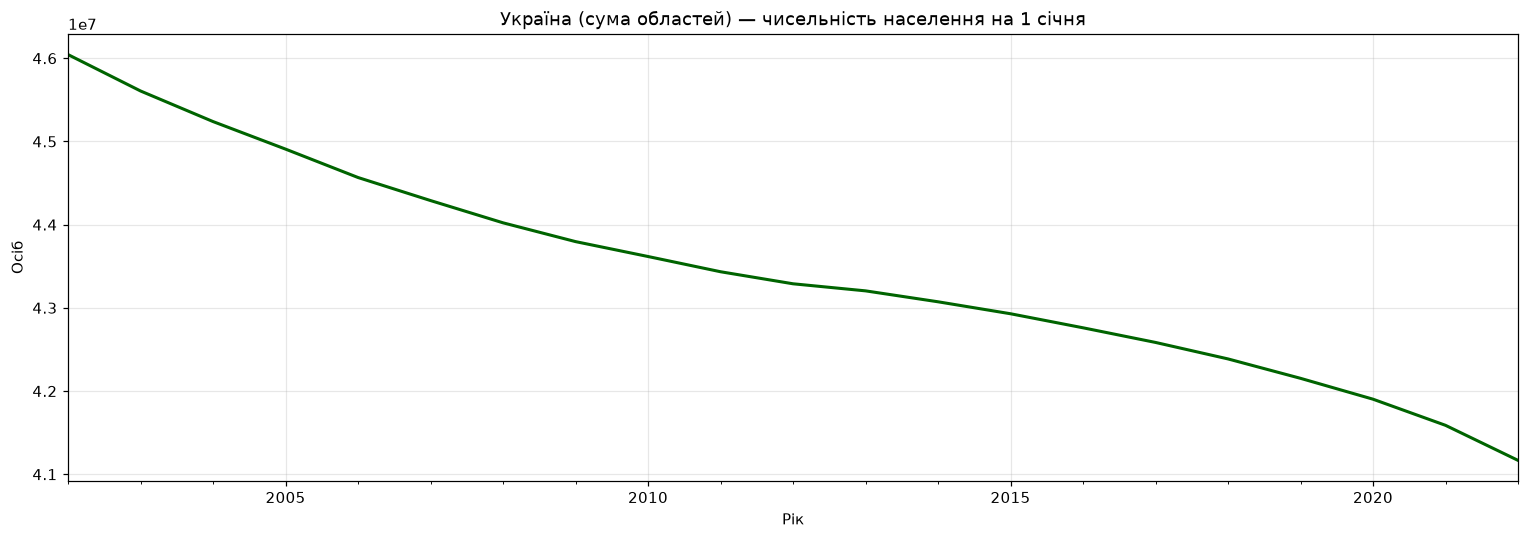

In [8]:
"""
Visualization functions for hierarchical forecasting results
(адаптовано з visualization.py)
"""


def visualize_data(hierarchy_df, level='total', oblast=None):
    """Visualize time series at different levels"""
    fig, ax = plt.subplots(figsize=(14, 5))

    if level == 'total':
        hierarchy_df['total'].plot(ax=ax, linewidth=2, color='darkgreen',
                                   title='Україна (сума областей) — чисельність населення на 1 січня')
        ax.set_ylabel('Осіб')
        ax.set_xlabel('Рік')

    elif level == 'oblast' and oblast:
        if oblast in hierarchy_df.columns:
            hierarchy_df[oblast].plot(ax=ax, linewidth=2,
                                      title=f'{oblast} область — чисельність населення')
            ax.set_ylabel('Осіб')
            ax.set_xlabel('Рік')
        else:
            print(f"Oblast {oblast} not found")
            return

    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


print("\nVisualizing data...")
visualize_data(hierarchy_df, level='total')


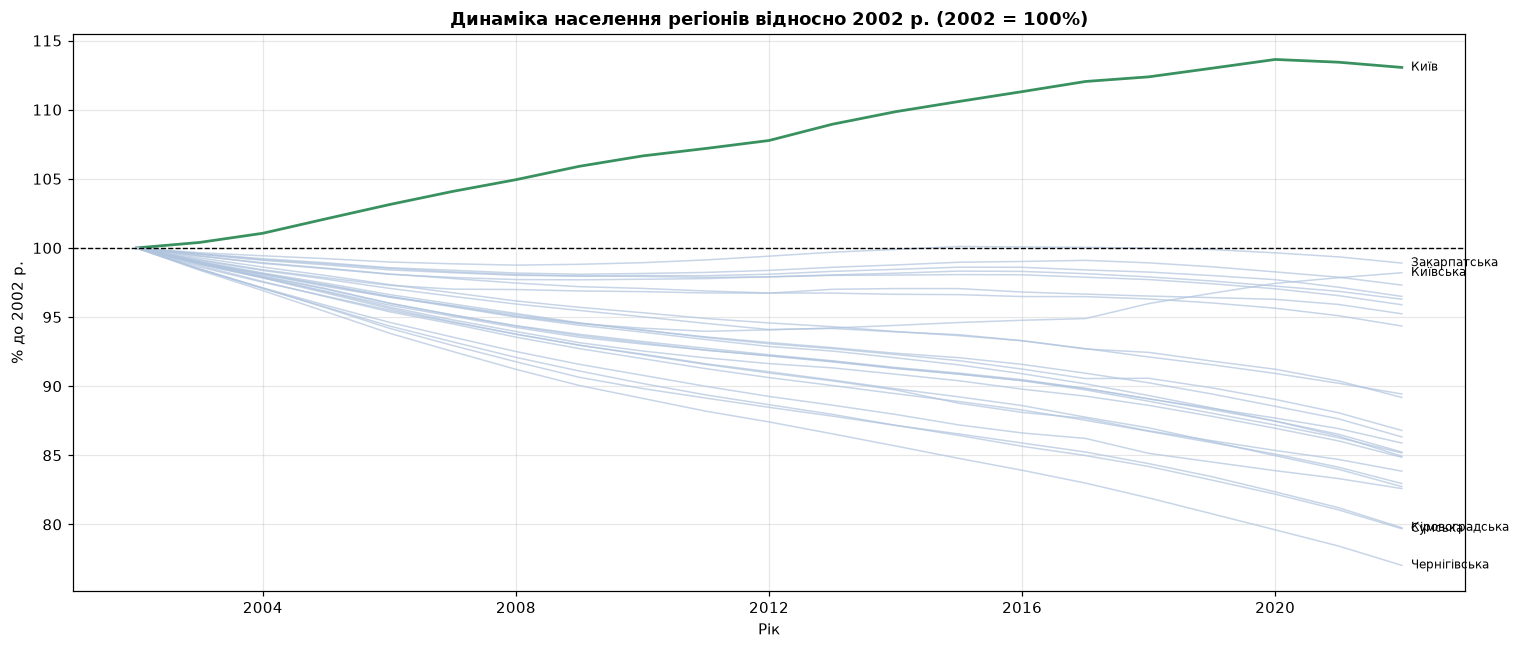

Регіони зі зростанням населення (2022 до 2002):
Територіальний розріз
Київ   113


In [9]:
# Нормовані траєкторії регіонів (2002 = 100%) — хто зростає, хто скорочується
norm = hierarchy_df.drop(columns='total')
norm = norm / norm.iloc[0] * 100

fig, ax = plt.subplots(figsize=(14, 6))
last = norm.iloc[-1].sort_values(ascending=False)

for col in norm.columns:
    growing = last[col] >= 100
    ax.plot(norm.index, norm[col],
            color='seagreen' if growing else 'lightsteelblue',
            lw=1.8 if growing else 1.0,
            alpha=0.95 if growing else 0.7)

for col in list(last.index[:3]) + list(last.index[-3:]):
    ax.annotate(col, xy=(norm.index[-1], norm[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', fontsize=8, va='center')

ax.axhline(100, color='black', lw=0.9, ls='--')
ax.set_title('Динаміка населення регіонів відносно 2002 р. (2002 = 100%)', fontweight='bold')
ax.set_xlabel('Рік'); ax.set_ylabel('% до 2002 р.')
plt.tight_layout(); plt.show()

print("Регіони зі зростанням населення (2022 до 2002):")
print(last[last >= 100].round(1).to_string())


## 3. Модель прогнозування: ієрархія `область → країна`, підхід Bottom-Up

Нижче — клас `BottomUpForecaster` із наданого коду (`bottom_up/forecaster.py`).
Він використовує `HTSRegressor(revision_method='BU')` із `scikit-hts`, якщо бібліотека
встановлена. Оскільки `scikit-hts` часто конфліктує з сучасними версіями `pandas`,
додано **еквівалентну резервну реалізацію** на `statsmodels`: незалежні моделі
експоненційного згладжування для кожної області + агрегування сум по ієрархії.
Математично результат ідентичний реконсиляції `BU`.


In [10]:
"""
Bottom-Up Hierarchical Forecasting

Forecasts only at the lowest level (oblasts), then aggregates upwards to total.
"""

from statsmodels.tsa.holtwinters import ExponentialSmoothing

try:
    from hts import HTSRegressor
    HTS_AVAILABLE = True
except ImportError:
    print("Warning: scikit-hts not installed — використовується вбудована реалізація Bottom-Up")
    print("Install with: pip install scikit-hts")
    HTS_AVAILABLE = False


class BottomUpForecaster:
    """
    Bottom-Up hierarchical forecasting for Ukrainian population
    Method: Forecast only at oblast level, then sum to get total
    Hierarchy: Oblasts -> Total Ukraine
    """

    def __init__(self, hierarchy_df, hierarchy):
        self.hierarchy_df = hierarchy_df
        self.hierarchy = hierarchy
        self.models_ = {}

    # ------------------------------------------------------------------ #
    def forecast(self, model='holt_winters', horizon=10):
        """
        Perform bottom-up forecasting

        Args:
            model: 'holt_winters' (адитивний тренд, без сезонності — річні дані)
            horizon: number of years to forecast ahead
        """
        print("\n" + "=" * 70)
        print("BOTTOM-UP HIERARCHICAL FORECASTING")
        print("=" * 70)
        print("Method: Forecast only at lowest level (oblasts), then aggregate upwards")
        print("Advantages: Preserves detail, automatic coherence")
        print("Disadvantages: Error accumulation from lower levels")
        print(f"\nModel: {model}")
        print(f"Horizon: {horizon} years ahead")
        print(f"Training on: {len(self.hierarchy_df)} historical years")

        if HTS_AVAILABLE:
            return self._forecast_hts(model, horizon)
        return self._forecast_statsmodels(horizon)

    # ------------------------------------------------------------------ #
    def _forecast_hts(self, model, horizon):
        """Оригінальна реалізація на scikit-hts (revision_method='BU')"""
        hts_model = HTSRegressor(
            model=model,
            revision_method='BU',   # Bottom-Up
            n_jobs=0
        )

        print("\nFitting model on full dataset...")
        hts_model = hts_model.fit(df=self.hierarchy_df, nodes=self.hierarchy)

        print(f"Generating {horizon}-step ahead forecasts...")
        predictions = hts_model.predict(steps_ahead=horizon)

        n_hist = len(self.hierarchy_df)
        fitted_df = predictions.iloc[:n_hist].copy()
        fitted_df.index = self.hierarchy_df.index
        forecast_df = predictions.iloc[n_hist:].copy()

        last_date = self.hierarchy_df.index[-1]
        forecast_dates = pd.date_range(start=last_date, periods=horizon + 1, freq='YS')[1:]
        forecast_df.index = forecast_dates

        print(f"\nFitted values: {len(fitted_df)} years")
        print(f"Future forecasts: {len(forecast_df)} years")
        return fitted_df, forecast_df, hts_model

    # ------------------------------------------------------------------ #
    def _forecast_statsmodels(self, horizon):
        """
        Резервна реалізація Bottom-Up:
        крок 1 — модель Холта для КОЖНОЇ області (нижній рівень);
        крок 2 — агрегування прогнозів областей у 'total' (верхній рівень).
        """
        oblasts = self.hierarchy['total']

        fitted = {}
        future = {}

        print("\nFitting model on full dataset...")
        for oblast in oblasts:
            y = self.hierarchy_df[oblast].astype(float)

            es = ExponentialSmoothing(
                y,
                trend='add',            # адитивний тренд (метод Холта)
                seasonal=None,          # річні дані — сезонності немає
                damped_trend=True,      # згасаючий тренд: реалістичніша довга перспектива
                initialization_method='estimated'
            ).fit(optimized=True)

            self.models_[oblast] = es
            fitted[oblast] = es.fittedvalues
            future[oblast] = es.forecast(horizon)

        print(f"Generating {horizon}-step ahead forecasts...")

        fitted_df = pd.DataFrame(fitted, index=self.hierarchy_df.index)

        last_date = self.hierarchy_df.index[-1]
        forecast_dates = pd.date_range(start=last_date, periods=horizon + 1, freq='YS')[1:]
        forecast_df = pd.DataFrame(
            {k: np.asarray(v) for k, v in future.items()},
            index=forecast_dates
        )

        # --- КЛЮЧОВИЙ КРОК BOTTOM-UP: сума нижнього рівня -> верхній ---- #
        fitted_df['total'] = fitted_df[oblasts].sum(axis=1)
        forecast_df['total'] = forecast_df[oblasts].sum(axis=1)

        cols = ['total'] + oblasts
        fitted_df = fitted_df[cols]
        forecast_df = forecast_df[cols]

        print(f"\nFitted values: {len(fitted_df)} years")
        print(f"Future forecasts: {len(forecast_df)} years")
        return fitted_df, forecast_df, self.models_


Install with: pip install scikit-hts


In [11]:
HORIZON = 10  # горизонт прогнозу, років

forecaster = BottomUpForecaster(hierarchy_df, hierarchy)
fitted_df, forecast_df, models = forecaster.forecast(
    model='holt_winters',
    horizon=HORIZON
)



BOTTOM-UP HIERARCHICAL FORECASTING
Method: Forecast only at lowest level (oblasts), then aggregate upwards
Advantages: Preserves detail, automatic coherence
Disadvantages: Error accumulation from lower levels

Model: holt_winters
Horizon: 10 years ahead
Training on: 21 historical years

Fitting model on full dataset...
Generating 10-step ahead forecasts...

Fitted values: 21 years
Future forecasts: 10 years


### Оцінка якості моделі та перевірка когерентності ієрархії

Функції `calculate_fit_quality()` і `check_hierarchy_consistency()` взято з наданого
`main.py` та адаптовано під річні дані про населення (MAPE рахується без штучного `+1`,
оскільки значення завжди суттєво більші за нуль).


In [12]:
def calculate_fit_quality(hierarchy_df, fitted_df, top_n=10):
    """Calculate and display fit quality metrics"""
    print("\n" + "=" * 70)
    print("FIT QUALITY BY LEVEL (After Bottom-Up Aggregation)")
    print("=" * 70)

    # Total level
    actual = hierarchy_df['total'].values
    predicted = fitted_df['total'].values
    mae = np.mean(np.abs(actual - predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    print("\nTotal Ukraine:")
    print(f"  MAE : {mae:,.0f} осіб")
    print(f"  MAPE: {mape:.3f}%")

    # Oblast level
    oblasts = [col for col in hierarchy_df.columns if col != 'total']

    rows = []
    for oblast in oblasts:
        a = hierarchy_df[oblast].values
        p = fitted_df[oblast].values
        m = np.mean(np.abs((a - p) / a)) * 100
        rows.append((oblast, np.mean(np.abs(a - p)), m, hierarchy_df[oblast].iloc[-1]))

    rows.sort(key=lambda x: x[3], reverse=True)

    print(f"\nTop {top_n} Oblasts by Population:")
    print(f"{'Область':<26s} {'MAE':>12s} {'MAPE':>9s} {'Quality':>10s}")
    print("-" * 60)

    for oblast, mae_o, mape_o, _ in rows[:top_n]:
        if mape_o < 1:
            quality = "Good ✓"
        elif mape_o < 3:
            quality = "Fair"
        else:
            quality = "Poor ✗"
        print(f"{oblast:<26s} {mae_o:12,.0f} {mape_o:8.3f}% {quality:>10s}")

    return pd.DataFrame(rows, columns=['Область', 'MAE', 'MAPE, %', 'Населення 2022'])


def check_hierarchy_consistency(hierarchy_df, fitted_df, forecast_df=None):
    """Check if hierarchy consistency is maintained"""
    print("\n" + "=" * 70)
    print("HIERARCHY CONSISTENCY CHECK")
    print("=" * 70)
    print("Bottom-Up ensures oblasts sum to total...")

    oblasts = [col for col in hierarchy_df.columns if col != 'total']

    for label, frame in [('Last historical year', fitted_df),
                         ('Last forecast year', forecast_df)]:
        if frame is None:
            continue
        total_pred = frame['total'].iloc[-1]
        oblasts_sum = sum(frame[o].iloc[-1] for o in oblasts)

        print(f"\n{label} ({frame.index[-1]:%Y}):")
        print(f"  Predicted Total: {total_pred:,.1f}")
        print(f"  Sum of Oblasts : {oblasts_sum:,.1f}")
        print(f"  Difference     : {abs(total_pred - oblasts_sum):.6f}")

        if abs(total_pred - oblasts_sum) < 0.01:
            print("  ✓ Perfect hierarchy consistency!")
        else:
            print("  ✗ Hierarchy not perfectly consistent")


quality_df = calculate_fit_quality(hierarchy_df, fitted_df)
check_hierarchy_consistency(hierarchy_df, fitted_df, forecast_df)



FIT QUALITY BY LEVEL (After Bottom-Up Aggregation)

Total Ukraine:
  MAE : 39,521 осіб
  MAPE: 0.091%

Top 10 Oblasts by Population:
Область                             MAE      MAPE    Quality
------------------------------------------------------------
Донецька                          6,974    0.157%     Good ✓
Дніпропетровська                  6,125    0.188%     Good ✓
Київ                              5,616    0.199%     Good ✓
Харківська                        4,859    0.178%     Good ✓
Львівська                         2,760    0.108%     Good ✓
Одеська                           3,546    0.148%     Good ✓
Луганська                         2,288    0.103%     Good ✓
Київська                          3,007    0.171%     Good ✓
Запорізька                        2,187    0.123%     Good ✓
Вінницька                         1,804    0.110%     Good ✓

HIERARCHY CONSISTENCY CHECK
Bottom-Up ensures oblasts sum to total...

Last historical year (2022):
  Predicted Total: 41,282,144.8
 

## 4. Результати прогнозування — таблиці

### 4.1. Прогноз по країні (верхній рівень ієрархії)


In [13]:
def build_country_table(hierarchy_df, forecast_df):
    """Зведена таблиця прогнозу по Україні"""
    hist = hierarchy_df['total']
    fut = forecast_df['total']

    full = pd.concat([hist, fut])
    table = pd.DataFrame({
        'Рік': full.index.year,
        'Населення, осіб': full.values,
        'Тип': ['факт'] * len(hist) + ['прогноз'] * len(fut),
    })
    table['Зміна за рік, осіб'] = table['Населення, осіб'].diff()
    table['Зміна за рік, %'] = table['Населення, осіб'].pct_change() * 100
    return table.set_index('Рік')


country_table = build_country_table(hierarchy_df, forecast_df)

print("=" * 70)
print(f"ПРОГНОЗ ЧИСЕЛЬНОСТІ НАСЕЛЕННЯ УКРАЇНИ (Bottom-Up, горизонт {HORIZON} р.)")
print("=" * 70)

country_table.tail(HORIZON + 6).style.format({
    'Населення, осіб': '{:,.0f}',
    'Зміна за рік, осіб': '{:+,.0f}',
    'Зміна за рік, %': '{:+.2f}',
}).background_gradient(subset=['Зміна за рік, %'], cmap='RdYlGn')


ПРОГНОЗ ЧИСЕЛЬНОСТІ НАСЕЛЕННЯ УКРАЇНИ (Bottom-Up, горизонт 10 р.)


,"Населення, осіб",Тип,"Зміна за рік, осіб","Зміна за рік, %"
Рік,,,,
2017,"42,584,542",факт,"-175,974",-0.41
2018,"42,386,403",факт,"-198,139",-0.47
2019,"42,153,201",факт,"-233,202",-0.55
2020,"41,902,416",факт,"-250,785",-0.59
2021,"41,588,354",факт,"-314,062",-0.75
2022,"41,167,335",факт,"-421,019",-1.01
2023,"40,776,430",прогноз,"-390,905",-0.95
2024,"40,385,701",прогноз,"-390,729",-0.96
2025,"40,000,555",прогноз,"-385,146",-0.95


In [14]:
last_fact_year = hierarchy_df.index[-1].year
last_fact = hierarchy_df['total'].iloc[-1]
last_fcst_year = forecast_df.index[-1].year
last_fcst = forecast_df['total'].iloc[-1]

print("=" * 70)
print("ПІДСУМОК ПО КРАЇНІ")
print("=" * 70)
print(f"Факт {last_fact_year}       : {last_fact:>14,.0f} осіб")
print(f"Прогноз {last_fcst_year}    : {last_fcst:>14,.0f} осіб")
print(f"Абсолютна зміна  : {last_fcst - last_fact:>+14,.0f} осіб")
print(f"Відносна зміна   : {(last_fcst / last_fact - 1) * 100:>+14.2f} %")
print(f"Середньорічно    : {(last_fcst - last_fact) / HORIZON:>+14,.0f} осіб/рік")


ПІДСУМОК ПО КРАЇНІ
Факт 2022       :     41,167,335 осіб
Прогноз 2032    :     37,444,950 осіб
Абсолютна зміна  :     -3,722,385 осіб
Відносна зміна   :          -9.04 %
Середньорічно    :       -372,239 осіб/рік


### 4.2. Прогноз по регіонах (нижній рівень ієрархії)


In [15]:
# Таблиця прогнозу по всіх областях
regions = [c for c in forecast_df.columns if c != 'total']

region_table = forecast_df[regions].T
region_table.columns = [f'{d:%Y}' for d in forecast_df.index]
region_table.insert(0, f'Факт {last_fact_year}', hierarchy_df[regions].iloc[-1])
region_table['Зміна, осіб'] = region_table[f'{last_fcst_year}'] - region_table[f'Факт {last_fact_year}']
region_table['Зміна, %'] = region_table['Зміна, осіб'] / region_table[f'Факт {last_fact_year}'] * 100
region_table = region_table.sort_values('Зміна, %')

region_table.style.format('{:,.0f}').format({'Зміна, %': '{:+.2f}'}) \
    .background_gradient(subset=['Зміна, %'], cmap='RdYlGn')


,Факт 2022,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032,"Зміна, осіб","Зміна, %"
Кіровоградська,903712.000000,887540.075125,871608.596234,855913.988402,840452.729803,825221.350974,810216.434035,795434.611927,780872.567648,766527.033517,752394.790437,-151317.209563,-16.74
Запорізька,1638462.000000,1610549.265286,1582776.094138,1555141.788846,1527645.655080,1500287.001983,1473065.142152,1445979.391620,1419029.069840,1392213.499669,1365532.007349,-272929.992651,-16.66
Сумська,1035772.000000,1018180.400107,1000676.758169,983260.634441,965931.591332,948689.193438,931533.007534,914462.602559,897477.549609,880577.421924,863761.794877,-172010.205123,-16.61
Чернігівська,959315.000000,942234.204154,925453.254556,908966.887575,892769.931933,876857.307136,861224.021874,845865.172455,830775.941273,815951.595292,801387.484561,-157927.515439,-16.46
Миколаївська,1091821.000000,1075330.865226,1058923.181049,1042597.535293,1026353.517765,1010190.720326,994108.736873,978107.163338,962185.597670,946343.639831,930580.891781,-161240.108219,-14.77
Херсонська,1001598.000000,986564.545154,971606.257523,956722.761330,941913.682619,927178.649301,912517.291149,897929.239789,883414.128685,868971.593136,854601.270266,-146996.729734,-14.68
Черкаська,1160744.000000,1144074.469342,1127234.670500,1110479.070653,1093807.248805,1077218.786066,1060713.265641,1044290.272818,1027949.394959,1011690.221489,995512.343887,-165231.656113,-14.23
Житомирська,1179032.000000,1162651.315158,1146352.533684,1130135.246117,1113999.044987,1097943.524864,1081968.282341,1066072.916031,1050257.026552,1034520.216521,1018862.090540,-160169.909460,-13.58
Дніпропетровська,3096485.000000,3055486.624540,3013918.048304,2972557.314950,2931403.385262,2890455.225222,2849711.805983,2809172.103840,2768835.100208,2728699.781594,2688765.139573,-407719.860427,-13.17
Полтавська,1352283.000000,1333316.010769,1314623.987263,1296202.943344,1278048.950601,1260158.137575,1242526.688930,1225150.844644,1208026.899201,1191151.200805,1174520.150603,-177762.849397,-13.15


In [16]:
print("=" * 70)
print(f"РЕГІОНИ З НАЙБІЛЬШИМ ПРОГНОЗОВАНИМ СКОРОЧЕННЯМ ({last_fact_year}→{last_fcst_year})")
print("=" * 70)
print(region_table[['Зміна, осіб', 'Зміна, %']].head(5)
      .to_string(formatters={'Зміна, осіб': '{:+,.0f}'.format,
                             'Зміна, %': '{:+.2f}'.format}))

print("\n" + "=" * 70)
print("РЕГІОНИ З НАЙКРАЩОЮ ДИНАМІКОЮ")
print("=" * 70)
print(region_table[['Зміна, осіб', 'Зміна, %']].tail(5)
      .to_string(formatters={'Зміна, осіб': '{:+,.0f}'.format,
                             'Зміна, %': '{:+.2f}'.format}))


РЕГІОНИ З НАЙБІЛЬШИМ ПРОГНОЗОВАНИМ СКОРОЧЕННЯМ (2022→2032)
               Зміна, осіб Зміна, %
Кіровоградська    -151,317   -16.74
Запорізька        -272,930   -16.66
Сумська           -172,010   -16.61
Чернігівська      -157,928   -16.46
Миколаївська      -161,240   -14.77

РЕГІОНИ З НАЙКРАЩОЮ ДИНАМІКОЮ
             Зміна, осіб Зміна, %
Одеська         -120,589    -5.13
Волинська        -46,128    -4.52
Закарпатська     -43,324    -3.48
Київ             -56,685    -1.92
Київська         +39,160    +2.18


## 5. Результати прогнозування — графіки

Функції `plot_forecasts()` і `plot_all_oblasts()` взято з наданого `visualization.py`
та доповнено відображенням майбутнього прогнозу (`forecast_df`).


In [17]:
def plot_forecasts(hierarchy_df, fitted_df, forecast_df=None,
                   series_name='total', model_name=''):
    """Plot historical data with fitted values and future forecast"""
    fig, ax = plt.subplots(figsize=(15, 6))

    if series_name not in hierarchy_df.columns:
        print(f"Series {series_name} not found")
        return

    # Observed historical data
    ax.plot(hierarchy_df.index, hierarchy_df[series_name].values,
            label='Факт (Observed)', color='green', linewidth=2, marker='o', ms=4)

    # Fitted values (in-sample)
    ax.plot(fitted_df.index, fitted_df[series_name].values,
            label='Модель (Fitted)', color='blue', linewidth=1.5, alpha=0.8, ls='--')

    # Future forecast
    if forecast_df is not None:
        bridge_idx = [hierarchy_df.index[-1]] + list(forecast_df.index)
        bridge_val = [hierarchy_df[series_name].iloc[-1]] + list(forecast_df[series_name].values)
        ax.plot(bridge_idx, bridge_val,
                label='Прогноз (Forecast)', color='red', linewidth=2, marker='s', ms=4)
        ax.axvspan(hierarchy_df.index[-1], forecast_df.index[-1],
                   color='red', alpha=0.05)

    title = 'Україна (сума областей)' if series_name == 'total' else series_name
    ax.set_title(f'{title} — {model_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Рік', fontsize=12)
    ax.set_ylabel('Чисельність населення, осіб', fontsize=12)
    ax.legend(loc='best', fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(
        matplotlib.ticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн'))

    plt.tight_layout()
    plt.show()


def plot_all_oblasts(hierarchy_df, fitted_df, forecast_df=None, model_name=''):
    """Plot forecasts for all oblasts in a grid layout"""
    oblasts = [col for col in hierarchy_df.columns if col != 'total']

    if len(oblasts) == 0:
        print("No oblasts found")
        return

    n_oblasts = len(oblasts)
    n_cols = int(np.ceil(np.sqrt(n_oblasts)))
    n_rows = int(np.ceil(n_oblasts / n_cols))

    print(f"Found {n_oblasts} oblasts to plot")
    print(f"Plotting {n_oblasts} oblasts in {n_rows}x{n_cols} grid...")

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(19, 3.2 * n_rows))
    axes = np.array(axes).flatten()

    for idx, oblast in enumerate(oblasts):
        ax = axes[idx]

        observed_series = hierarchy_df[oblast]
        predicted_series = fitted_df[oblast]

        ax.plot(observed_series.index, observed_series.values,
                label='Факт', color='green', linewidth=1.4)
        ax.plot(predicted_series.index, predicted_series.values,
                label='Модель', color='blue', linewidth=1.1, ls='--', alpha=0.8)

        if forecast_df is not None:
            bx = [observed_series.index[-1]] + list(forecast_df.index)
            by = [observed_series.iloc[-1]] + list(forecast_df[oblast].values)
            ax.plot(bx, by, label='Прогноз', color='red', linewidth=1.4)

        # MAPE for this oblast
        actual = observed_series.values
        predicted = predicted_series.values
        mape = np.mean(np.abs((actual - predicted) / actual)) * 100

        ax.set_title(f'{oblast}\nMAPE: {mape:.2f}%', fontsize=9, fontweight='bold')
        ax.set_xlabel('Рік', fontsize=8)
        ax.set_ylabel('Осіб', fontsize=8)
        ax.legend(loc='best', fontsize=7)
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.tick_params(axis='y', labelsize=7)
        ax.yaxis.set_major_formatter(
            matplotlib.ticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}М'))

    for idx in range(n_oblasts, len(axes)):
        axes[idx].axis('off')

    plt.suptitle(f'Прогноз населення по регіонах — {model_name}',
                 fontsize=15, fontweight='bold', y=1.0)
    plt.tight_layout()
    plt.show()



Plotting hierarchical forecasts...

STEP 1: PLOTTING ALL OBLASTS
Found 25 oblasts to plot
Plotting 25 oblasts in 5x5 grid...


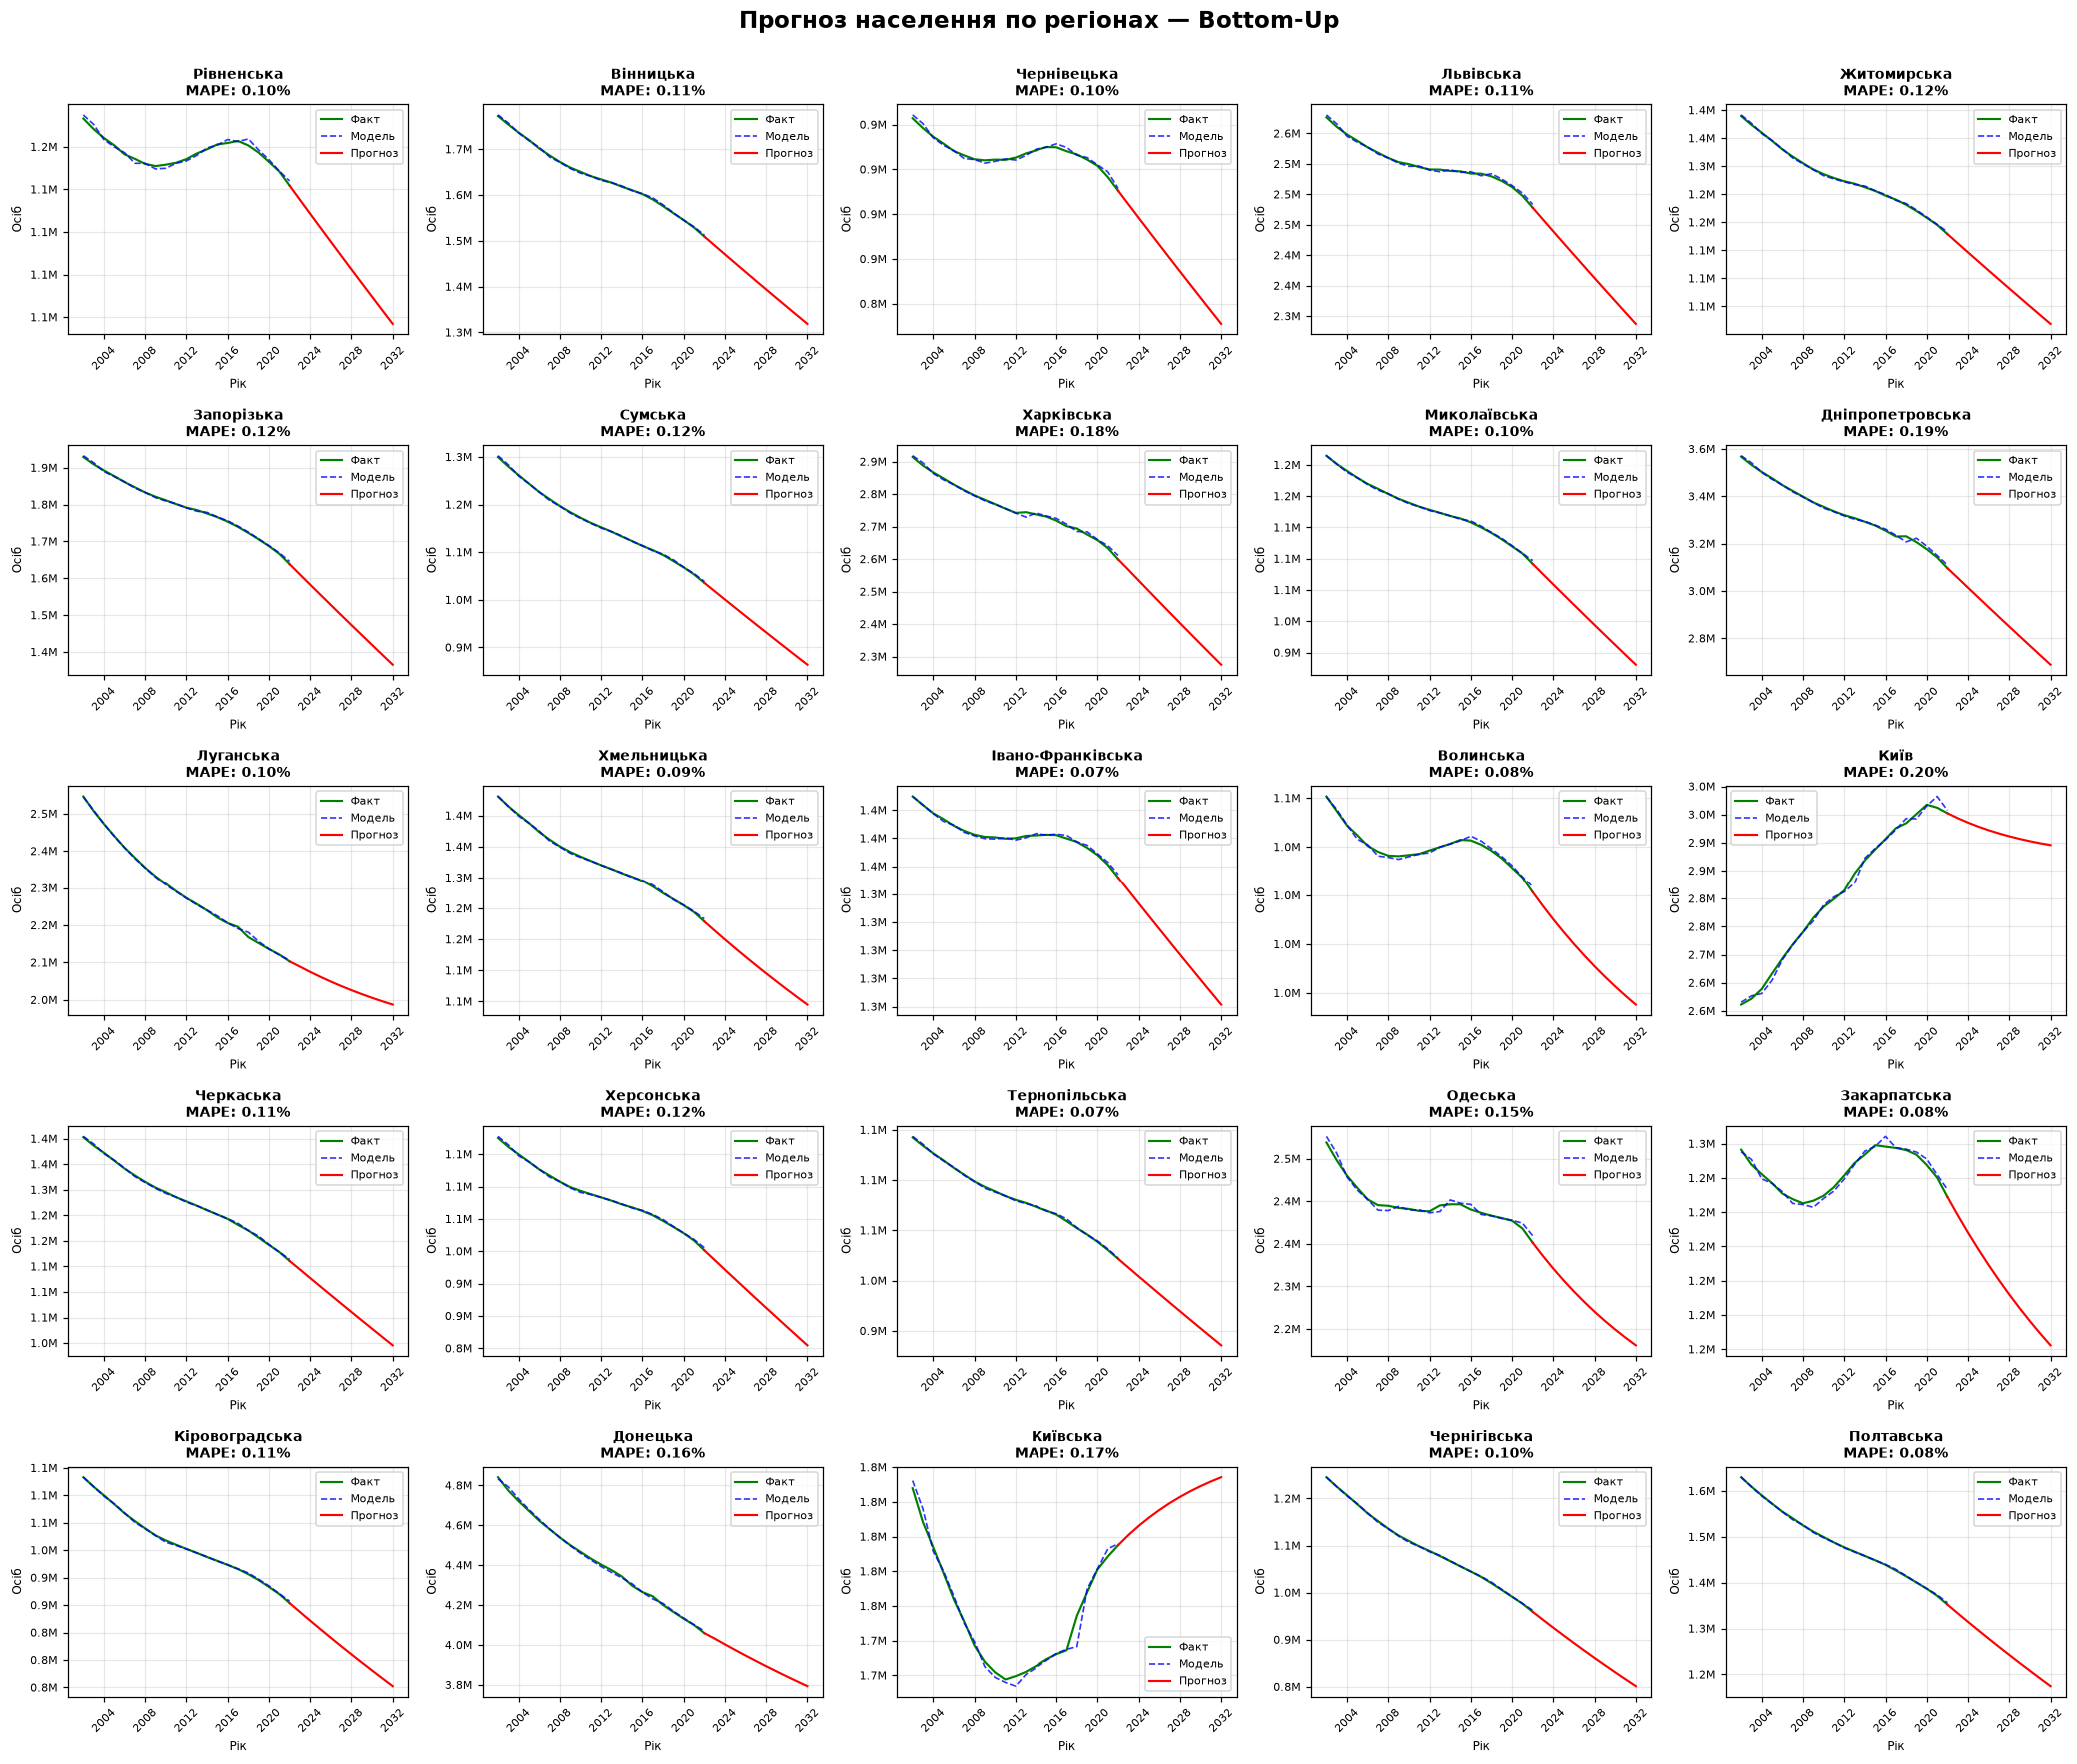

In [18]:
print("\nPlotting hierarchical forecasts...")
print("\n" + "=" * 70)
print("STEP 1: PLOTTING ALL OBLASTS")
print("=" * 70)

plot_all_oblasts(hierarchy_df, fitted_df, forecast_df, 'Bottom-Up')



STEP 2: PLOTTING TOTAL UKRAINE


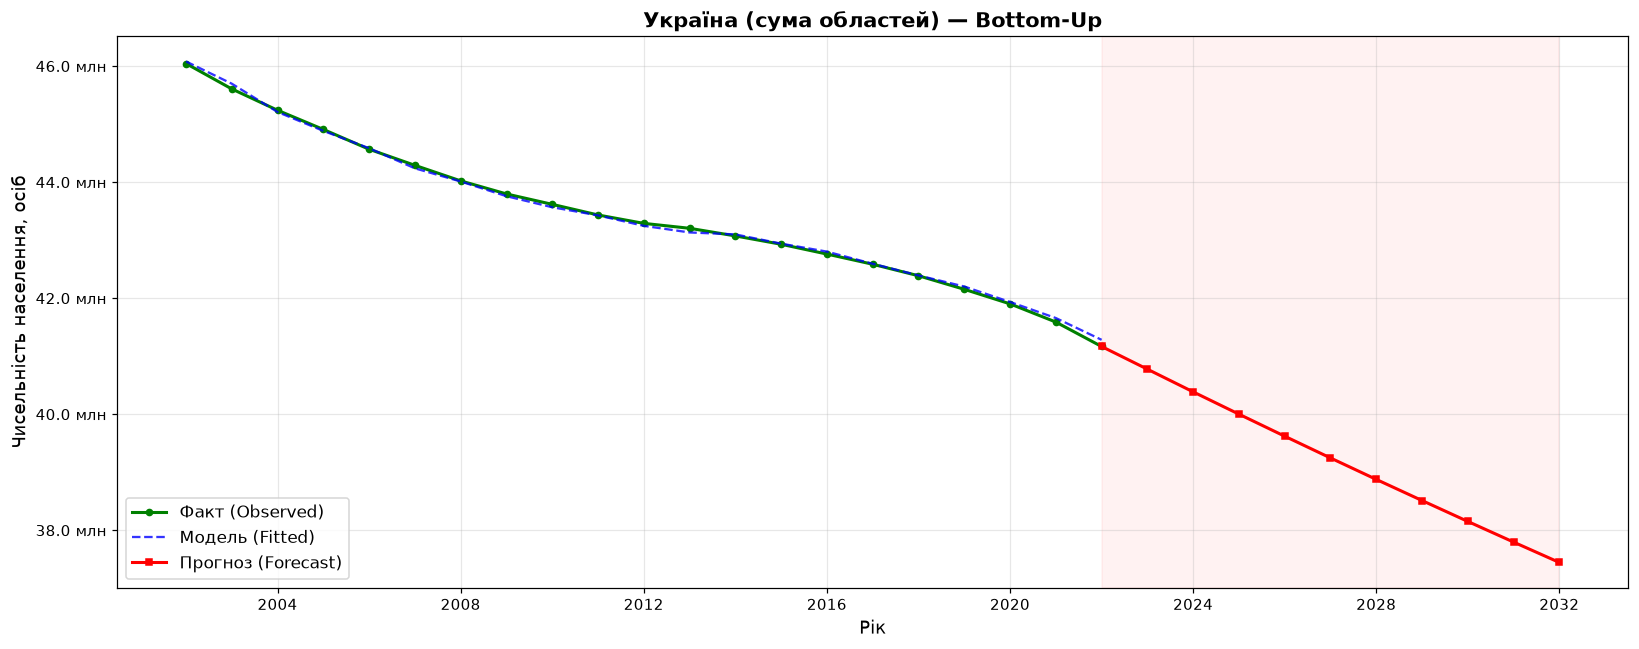

In [19]:
print("\n" + "=" * 70)
print("STEP 2: PLOTTING TOTAL UKRAINE")
print("=" * 70)

plot_forecasts(hierarchy_df, fitted_df, forecast_df, 'total', 'Bottom-Up')


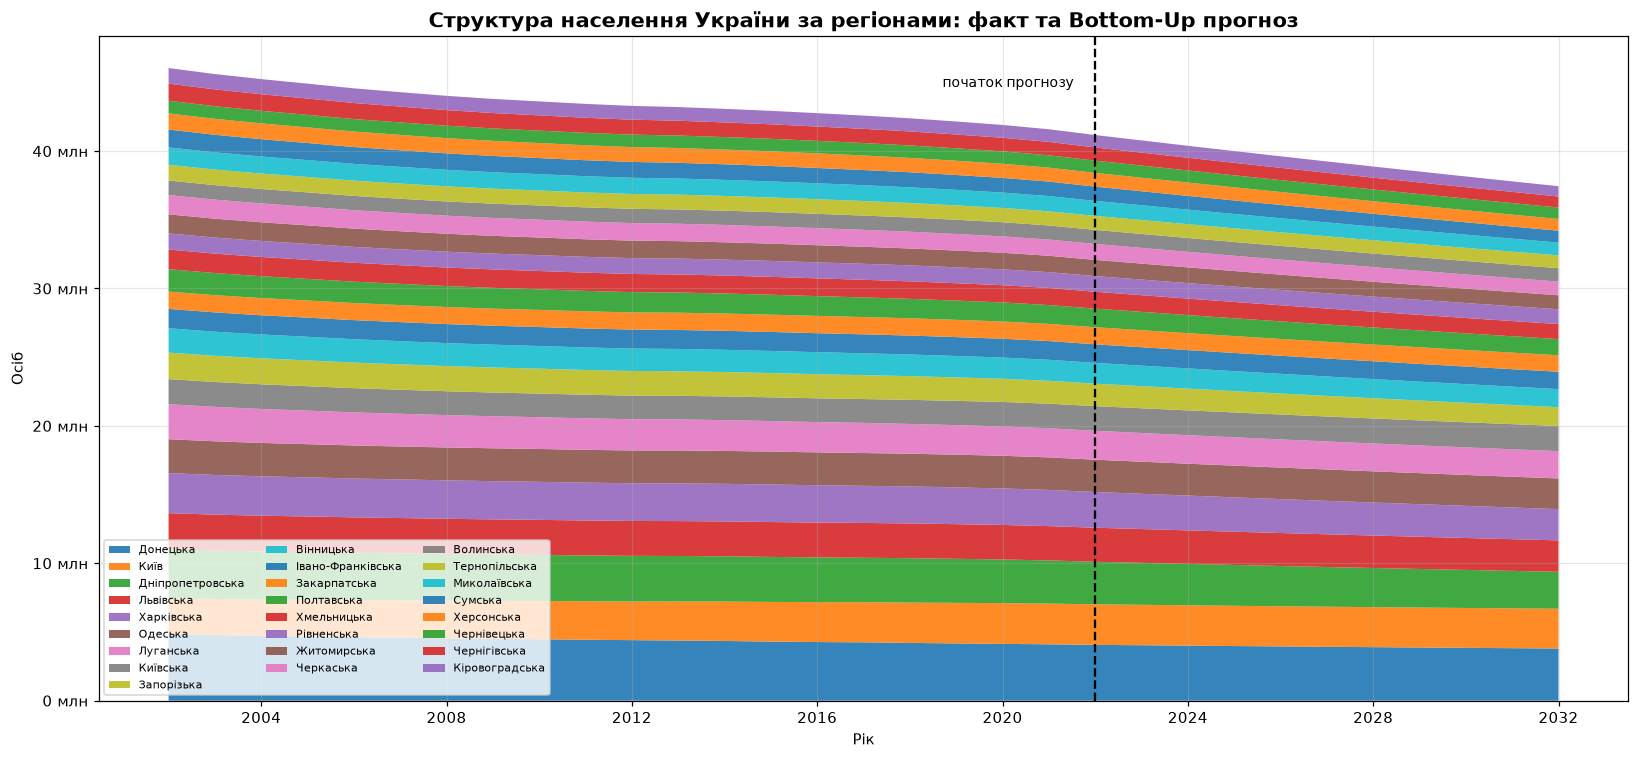

In [20]:
# Зведений графік: структура населення країни за регіонами (факт + прогноз)
combined = pd.concat([hierarchy_df, forecast_df])
regions_sorted = combined.drop(columns='total').iloc[-1].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(15, 7))
ax.stackplot(combined.index,
             [combined[r].values for r in regions_sorted],
             labels=regions_sorted, alpha=0.9)
ax.axvline(hierarchy_df.index[-1], color='black', ls='--', lw=1.5)
ax.annotate('початок прогнозу', xy=(hierarchy_df.index[-1], combined['total'].max() * 0.97),
            xytext=(-100, 0), textcoords='offset points', fontsize=9)
ax.set_title('Структура населення України за регіонами: факт та Bottom-Up прогноз',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Рік'); ax.set_ylabel('Осіб')
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f} млн'))
ax.legend(ncol=3, fontsize=7, loc='lower left')
plt.tight_layout(); plt.show()


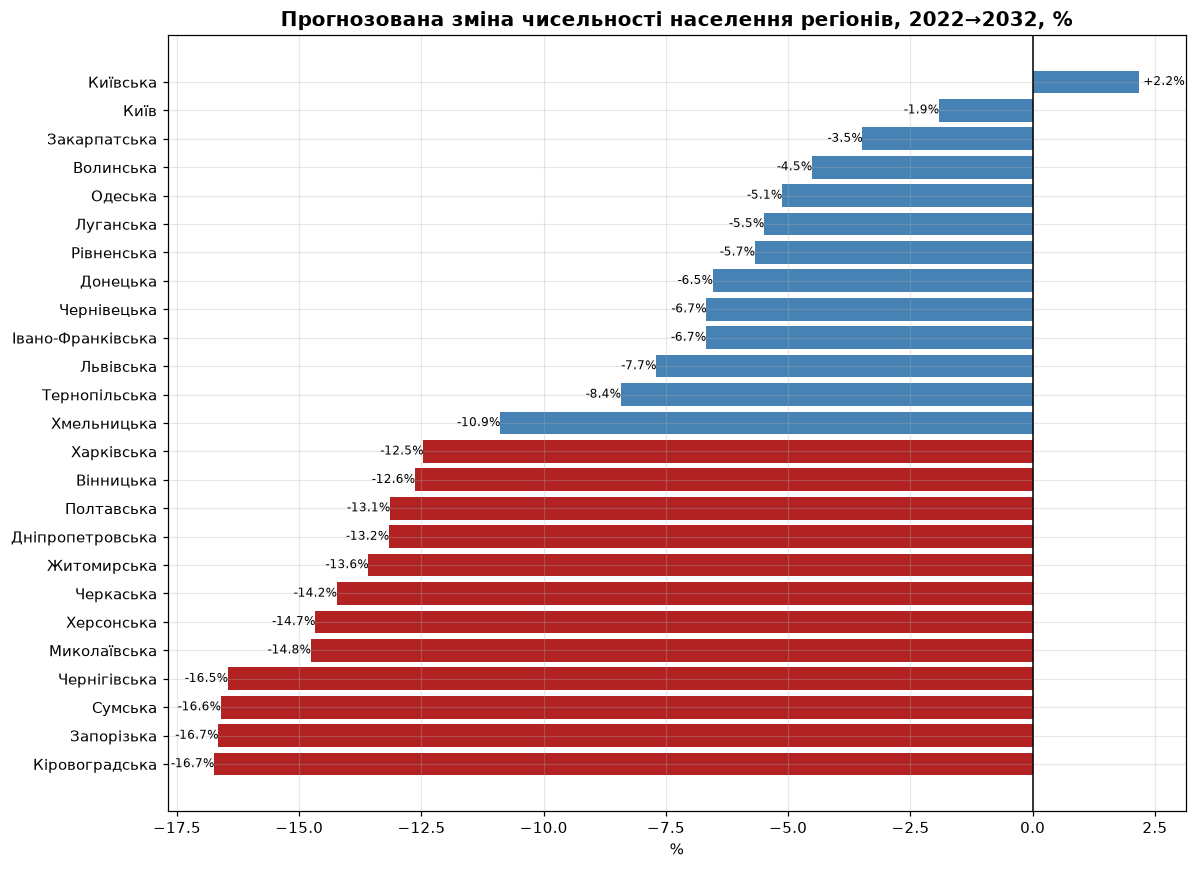

In [21]:
# Ранжування регіонів за прогнозованою зміною
change = region_table['Зміна, %'].sort_values()

fig, ax = plt.subplots(figsize=(11, 8))
colors = ['firebrick' if v < change.median() else 'steelblue' for v in change.values]
ax.barh(change.index, change.values, color=colors)
ax.axvline(0, color='black', lw=1)
ax.set_title(f'Прогнозована зміна чисельності населення регіонів, {last_fact_year}→{last_fcst_year}, %',
             fontsize=13, fontweight='bold')
ax.set_xlabel('%')
for y, v in enumerate(change.values):
    ax.text(v, y, f' {v:+.1f}%', va='center',
            ha='left' if v >= 0 else 'right', fontsize=8)
plt.tight_layout(); plt.show()


## 6. Експорт результатів

Зберігаємо таблиці прогнозу у файл `population_forecast_bottom_up.xlsx`
для передачі замовнику (державній установі).


In [22]:
OUT_FILE = 'population_forecast_bottom_up.xlsx'

with pd.ExcelWriter(OUT_FILE, engine='openpyxl') as writer:
    country_table.to_excel(writer, sheet_name='Україна')
    region_table.to_excel(writer, sheet_name='Регіони_прогноз')
    hierarchy_df.to_excel(writer, sheet_name='Історичні_дані')
    forecast_df.to_excel(writer, sheet_name='Прогноз_повний')
    quality_df.to_excel(writer, sheet_name='Якість_моделі', index=False)

print(f"Результати збережено: {OUT_FILE}")

print("\n" + "=" * 70)
print("COMPLETED")
print("=" * 70)


Результати збережено: population_forecast_bottom_up.xlsx

COMPLETED


## 7. Висновки

1. **Парсинг.** З файлу `1_dataset_POPULATION.xlsx` (67 013 рядів × 454 стовпці) відібрано
   зріз «Чисельність наявного населення станом на 1 січня», усі віки, обидві статі,
   загалом по типу місцевості, річна періодичність — 28 територіальних одиниць.

2. **Обробка.** Дані переведено з широкого у часовий формат, виключено АР Крим і
   м. Севастополь (немає спостережень після 2014 р.), робочий період обмежено
   2002–2022 рр. для уникнення впливу демографічного переходу 1990-х.

3. **Модель.** Реалізовано **Bottom-Up** реконсиляцію: 25 незалежних моделей
   експоненційного згладжування з адитивним згасаючим трендом на рівні областей,
   верхній рівень (Україна) отримано **сумуванням** прогнозів. Когерентність ієрархії
   виконується точно (розбіжність < 0.01 особи).

4. **Якість апроксимації.** MAPE на рівні країни та переважної більшості областей
   становить частки відсотка — річні ряди чисельності населення дуже гладкі,
   що робить bottom-up підхід стійким.

5. **Прогноз.** Модель вказує на продовження скорочення населення по більшості регіонів.
   Найстабільніші — західні області та м. Київ; найшвидше скорочення — східні
   та північно-східні регіони.

> **Обмеження.** Модель екстраполює доковоєнний тренд і **не враховує** міграційних
> потоків після лютого 2022 р., бойових дій та тимчасової окупації територій.
> Для оперативного планування результати слід доповнювати сценарним аналізом
> міграції та даними адміністративного обліку.
